# Q1. Camera

## (a)

### Task:
In Assignment 1, Q1, find the coordinates of the centre of the swinging load,
o1 (x, y, z) for all frames in training set rgb_train_val_swingingload.avi.
Use the M_int obtained in the Lab. Plot the 3D coordinates of swinging load for all frames.

### Approach:
1. Define the matrix from lab

2. Find the center pixel (u, v) of the swinging load in each frame and get the corresponding depth value.

3. Use the intrinsic matrix M_int to convert (u, v, depth) into 3D camera coordinates (X, Y, Z).

4. Save the 3D coordinates for all frames and plot the complete 3D trajectory.

In [1]:
import numpy as np

#1 Intrinsic matrix from lab
M_int = np.array([
    [1391.71768, 0.0, 979.101974],
    [0.0, 1388.53250, 540.246062],
    [0.0, 0.0, 1.0]
])
print(M_int)



[[1.39171768e+03 0.00000000e+00 9.79101974e+02]
 [0.00000000e+00 1.38853250e+03 5.40246062e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


In [3]:
#2 finding the RGB files, and depth filene.

from pathlib import Path
import cv2

rgb_folder = Path("Data/Train/rgb_frames")
depth_folder = Path("Data/Train/depth_raw")
rgb_files = sorted(rgb_folder.glob("*.png"))
depth_files = sorted(depth_folder.glob("*.npy"))

print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))

RGB frames: 900
Depth frames: 900


In [4]:
#Picking up the yolo model for swinging load detection 

from ultralytics import YOLO
model = YOLO("YOLO_swinging_load.pt")

In [5]:
import json
#checks that the RGB frames, depth frames and depth-scale files are available,
#  and reads the depth scale needed to convert the raw depth values.

scale_folder = Path("Data/Train/depth_scale_json")
scale_files = sorted(scale_folder.glob("*.json"))

#print the number of RGB frames, depth frames, and depth scale files found, along with examples of each.
print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))
print("Depth scale files:", len(scale_files))
print("Example RGB file:", rgb_files[0].name)
print("Example depth file:", depth_files[0].name)

#examines the first depth scale file, reads its content, and prints it out.
if scale_files:
    print("Example scale file:", scale_files[0].name)

    with open(scale_files[0], "r") as f:
        scale_data = json.load(f)

    print("Depth scale content:", scale_data)

RGB frames: 900
Depth frames: 900
Depth scale files: 1
Example RGB file: rgb_0000.png
Example depth file: depth_0000_raw.npy
Example scale file: depth_scale.json
Depth scale content: {'depth_scale': 0.0002500000118743628, 'timestamp': '20260918_152400'}


In [19]:
depth_values = []
centers = []

for rgb_path, depth_path in zip(rgb_files, depth_files):

    result = model.predict(str(rgb_path), verbose=False)[0]

    if result.boxes is None or len(result.boxes) == 0:
        continue

    i = int(result.boxes.conf.argmax())
    x1, y1, x2, y2 = result.boxes.xyxy[i].cpu().numpy()

    u = int((x1 + x2) / 2)
    v = int((y1 + y2) / 2)

    depth_raw = np.load(depth_path)

    # New fallback depth method
    if depth_raw[v, u] > 0:
        depth = depth_raw[v, u] * depth_scale

    else:
        x1i, y1i = max(0, int(x1)), max(0, int(y1))
        x2i = min(depth_raw.shape[1], int(x2))
        y2i = min(depth_raw.shape[0], int(y2))

        box_depth = depth_raw[y1i:y2i, x1i:x2i]

        valid_y, valid_x = np.where(box_depth > 0)

        if len(valid_x) > 0:
            valid_x = valid_x + x1i
            valid_y = valid_y + y1i

            distances = (valid_x - u)**2 + (valid_y - v)**2
            nearest = np.argmin(distances)

            depth = depth_raw[
                valid_y[nearest],
                valid_x[nearest]
            ] * depth_scale
        else:
            depth = np.nan

    centers.append((u, v))
    depth_values.append(depth)

In [20]:
valid_depths = np.sum(~np.isnan(depth_values))
nan_depths = np.sum(np.isnan(depth_values))

print("Valid depth values:", valid_depths)
print("Missing depth values:", nan_depths)

Valid depth values: 889
Missing depth values: 0


### Depth handling

We found that many of the center pixels had a depth value of 0, which means that there was no valid depth value at that exact pixel.

To solve this, we first used the depth value at the center pixel if it was available. If not, we used the closest valid depth value inside the YOLO bounding box.

This reduced the missing depth values from 336 to 0 for the 889 frames where the load was detected.

YOLO detected the swinging load in 889 of 900 frames.

In [38]:
# Remove large depth outliers using a local median

depth_array = np.array(depth_values, dtype=float)

window = 7
half_window = window // 2

depth_clean = depth_array.copy()

for i in range(len(depth_array)):
    start = max(0, i - half_window)
    end = min(len(depth_array), i + half_window + 1)

    local_median = np.median(depth_array[start:end])

    if abs(depth_array[i] - local_median) > 0.5:
        depth_clean[i] = np.nan

# Interpolate the removed outliers
valid = ~np.isnan(depth_clean)

depth_clean = np.interp(
    np.arange(len(depth_clean)),
    np.arange(len(depth_clean))[valid],
    depth_clean[valid]
)

print("Number of corrected depth values:",
      np.sum(np.abs(depth_array - depth_clean) > 0))

Number of corrected depth values: 70


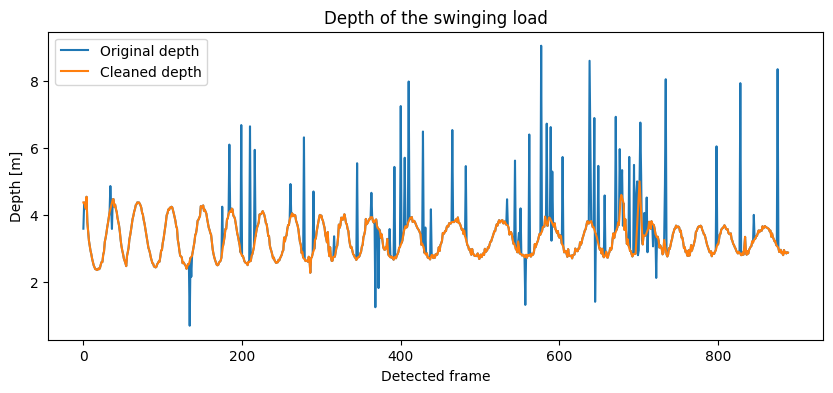

In [39]:
plt.figure(figsize=(10, 4))

plt.plot(depth_array, label="Original depth")
plt.plot(depth_clean, label="Cleaned depth")

plt.xlabel("Detected frame")
plt.ylabel("Depth [m]")
plt.title("Depth of the swinging load")
plt.legend()

plt.show()

In [47]:
# Step 3: Convert pixel coordinates and depth to 3D coordinates using the intrinsic matrix

fx = M_int[0, 0]
fy = M_int[1, 1]
cx = M_int[0, 2]
cy = M_int[1, 2]

o1 = []

for (u, v), depth in zip(centers, depth_clean):
    

    Z = depth
    X = (u - cx) * Z / fx
    Y = (v - cy) * Z / fy

    o1.append([X, Y, Z])

o1 = np.array(o1)

print("Number of 3D coordinates:", len(o1))
print("First 3D coordinate [X, Y, Z]:", o1[0])

Number of 3D coordinates: 889
First 3D coordinate [X, Y, Z]: [    -1.8052     -1.0079      4.3838]


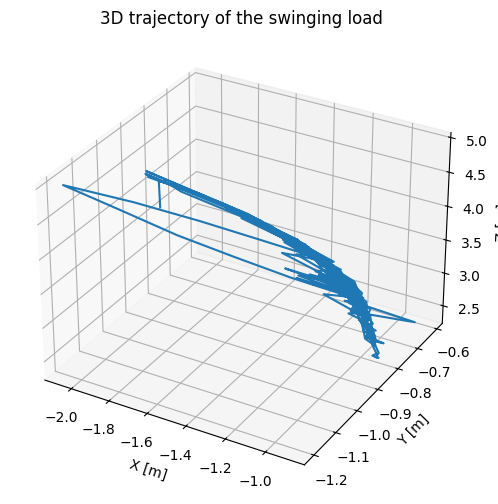

In [48]:
# Step 4: Plot the 3D trajectory

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(o1[:, 0], o1[:, 1], o1[:, 2])

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("3D trajectory of the swinging load")

plt.show()

### Depth filtering

The depth data contained several large spikes that did not match the continuous movement of the swinging load. Depth measurements can contain unreliable values, and depth filtering can therefore be used to remove unreliable measurements.

A local median was used to identify large depth outliers. Values that differed more than 0.5 m from the local median were treated as outliers and replaced by interpolation between neighbouring valid values.

The threshold was chosen based on the observed depth data to remove the clear spikes while keeping the general movement of the load.
YOLO detected the swinging load in 889 of 900 frames.


## (b)

### Task:
Say, the default intrinsic matrix of L515 is

\[
M_d =
\begin{bmatrix}
1342 & 0 & 325 \\
0 & 1342 & 235 \\
0 & 0 & 1
\end{bmatrix}
\]

Use this matrix to find the 3D coordinates of the center of the swinging load for all frames \((o_2)\) and plot them.

### Approach:
1. Define the default intrinsic matrix \(M_d\).

2. Use the same center pixel \((u, v)\) and depth values found in part (a).

3. Use \(M_d\) to convert \((u, v, depth)\) into 3D camera coordinates \((X, Y, Z)\).

4. Save the 3D coordinates as \(o_2\) and plot the complete 3D trajectory.

In [49]:
# Step 1: Define the default intrinsic matrix Md

Md = np.array([
    [1342.0, 0.0, 325.0],
    [0.0, 1342.0, 235.0],
    [0.0, 0.0, 1.0]
])

print(Md)

[[       1342           0         325]
 [          0        1342         235]
 [          0           0           1]]


In [50]:
# Step 2: Get the parameters from Md

fx_d = Md[0, 0]
fy_d = Md[1, 1]
cx_d = Md[0, 2]
cy_d = Md[1, 2]

print("fx:", fx_d)
print("fy:", fy_d)
print("cx:", cx_d)
print("cy:", cy_d)

fx: 1342.0
fy: 1342.0
cx: 325.0
cy: 235.0


In [51]:
# Step 3: Calculate 3D coordinates using Md

o2 = []

for (u, v), depth in zip(centers, depth_clean):

    Z = depth
    X = (u - cx_d) * Z / fx_d
    Y = (v - cy_d) * Z / fy_d

    o2.append([X, Y, Z])

o2 = np.array(o2)

print("Number of 3D coordinates:", len(o2))
print("First 3D coordinate [X, Y, Z]:", o2[0])

Number of 3D coordinates: 889
First 3D coordinate [X, Y, Z]: [    0.26459   -0.045732      4.3838]


In [52]:
print("o1 first point:", o1[0])
print("o2 first point:", o2[0])

o1 first point: [    -1.8052     -1.0079      4.3838]
o2 first point: [    0.26459   -0.045732      4.3838]


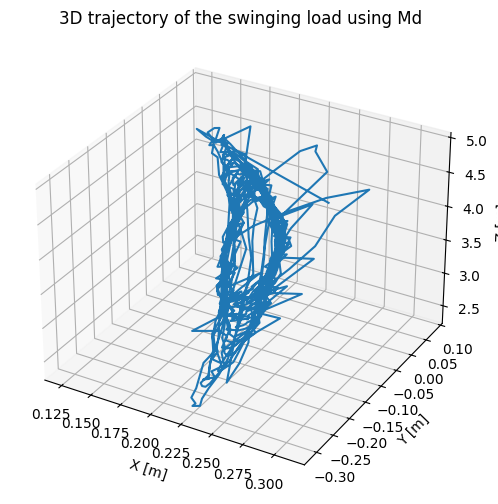

In [53]:
# Step 4: Plot the 3D trajectory using Md

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(o2[:, 0], o2[:, 1], o2[:, 2])

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("3D trajectory of the swinging load using Md")

plt.show()

The same detected center pixels and cleaned depth values from part (a) were used. The default intrinsic matrix \(M_d\) was then used to calculate the 3D coordinates o_2

## (c)

### Task:
Which intrinsic matrix, \(M_{int}\) or \(M_d\), is more accurate? Give reasons for the answer.

### Approach:
1. Compare the intrinsic parameters in \(M_{int}\) and \(M_d\).
2. Compare the principal point values with the image resolution.
3. Compare the focal length values with the camera specification.
4. Use the resulting 3D trajectories to support the conclusion.

In [54]:
# Compare intrinsic parameters

print("M_int:")
print("fx =", M_int[0, 0])
print("fy =", M_int[1, 1])
print("cx =", M_int[0, 2])
print("cy =", M_int[1, 2])

print("\nMd:")
print("fx =", Md[0, 0])
print("fy =", Md[1, 1])
print("cx =", Md[0, 2])
print("cy =", Md[1, 2])

M_int:
fx = 1391.71768
fy = 1388.5325
cx = 979.101974
cy = 540.246062

Md:
fx = 1342.0
fy = 1342.0
cx = 325.0
cy = 235.0


### Answer:

The default intrinsic matrix M_d seems to be more accurate for the images used in this assignment.

The images have a resolution of 640 × 480 pixels, so the image center is approximately (320, 240). The principal point in M_d is (325, 235), which is very close to the image center. In comparison, the principal point in \(M_{int}\) is approximately (979, 540), which does not match the image resolution used here.

The lecture notes also show that the focal length for the L515/OV2740 camera is approximately 1285 pixels. The focal length in M_d is 1342 pixels, while (M_{int} gives approximately 1390 pixels. Therefore, \(M_d\) is also closer to the expected focal length.

Based on both the principal point and the focal length, M_d appears to be more suitable for the 640 × 480 images used in this assignment.

## (d)

### Task:
From the data obtained in part (a) and (b), \(o_1\) and \(o_2\), implement a machine learning model that learns the function

\[
f_\theta(o_1) = o_2^*
\]

and evaluate the model using relevant KPIs.

### Approach:
1. Use \(o_1\) as input data and \(o_2\) as target data.
2. Split the data into training and test sets.
3. Train a regression model to learn the relationship between \(o_1\) and \(o_2\).
4. Predict \(o_2^*\) from the test data.
5. Evaluate the model using relevant regression KPIs.

In [58]:
# Step 1: Prepare input and target data

from sklearn.model_selection import train_test_split

X = o1
y = o2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 711
Test samples: 178


In [59]:
# Step 2: Train a linear regression model

from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

print("Model trained")

Model trained


In [60]:
# Step 3: Predict o2* from the test data

o2_star = model_lr.predict(X_test)

print("Number of predictions:", len(o2_star))
print("First predicted coordinate [X, Y, Z]:", o2_star[0])
print("First actual coordinate [X, Y, Z]:", y_test[0])

Number of predictions: 178
First predicted coordinate [X, Y, Z]: [    0.22369    -0.17463      2.6333]
First actual coordinate [X, Y, Z]: [    0.22369    -0.17463      2.6333]


In [61]:
# Step 4: Evaluate the model using RMSE

from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test, o2_star))

print("RMSE:", rmse)

RMSE: 7.60695865875571e-16


In [62]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, o2_star)

print("R²:", r2)

R²: 1.0


### Results


The linear regression model predicted \(o_2\) very accurately from \(o_1\).

The RMSE was almost 0, meaning that there was almost no difference between the predicted and actual coordinates. The \(R^2\) value was 1.0, which shows that the model explains the relationship between \(o_1\) and \(o_2\) very well.

This makes sense since \(o_1\) and \(o_2\) are calculated from the same pixel and depth data, but with different intrinsic matrices.

## (e)

### Task:
Find the Euclidean error between:

1. \(o_1\) and \(o_2\)
2. \(o_1\) and \(o_2^*\)

and interpret the results.

### Approach:
1. Calculate the Euclidean distance between corresponding coordinates in \(o_1\) and \(o_2\).
2. Calculate the Euclidean distance between the test coordinates from \(o_1\) and the predicted coordinates \(o_2^*\).
3. Compare the errors and interpret the results.

In [63]:
# Step 1: Euclidean error between o1 and o2

error_o1_o2 = np.linalg.norm(o1 - o2, axis=1)

print("Mean Euclidean error o1 vs o2:", np.mean(error_o1_o2))
print("Minimum error:", np.min(error_o1_o2))
print("Maximum error:", np.max(error_o1_o2))

Mean Euclidean error o1 vs o2: 1.718149976340038
Minimum error: 1.1893629459818396
Maximum error: 2.6103445327317347


In [64]:
# Step 2: Euclidean error between o1 and o2*

error_o1_o2star = np.linalg.norm(X_test - o2_star, axis=1)

print("Mean Euclidean error o1 vs o2*:", np.mean(error_o1_o2star))
print("Minimum error:", np.min(error_o1_o2star))
print("Maximum error:", np.max(error_o1_o2star))

Mean Euclidean error o1 vs o2*: 1.713289468376552
Minimum error: 1.2926944485881782
Maximum error: 2.2808724171985504


### Results

The mean Euclidean error between \(o_1\) and \(o_2\) was about 1.72 m, while the mean error between \(o_1\) and \(o_2^*\) was about 1.71 m.

The errors are very similar because the linear regression model predicted \(o_2\) very accurately, so \(o_2^*\) is very close to \(o_2\).

The difference from \(o_1\) mainly comes from using different intrinsic matrices when calculating the 3D coordinates.

# Q2. Lidar

## (a)

### Task:
Use Ouster lidar data to find the center of the swinging load for all frames and plot the trajectory.

### Approach:
1. Load the lidar point cloud data for each frame.
2. Use clustering to separate the swinging load from the other points in the scene.
3. Find the centroid of the cluster representing the swinging load.
4. Save the centroid for each frame and plot the complete 3D trajectory.

### Data and method

The supplied Ouster OS-1 recording is read with its matching sensor metadata. Each complete scan is converted to XYZ points in metres. For part (a), DBSCAN isolates the compact moving load cluster in a checked region of the sensor frame, and the mean XYZ of that cluster is tracked across scans. Part (b) applies KISS-ICP to consecutive complete scans to estimate sensor motion. Sensor pose and load-centroid position are different quantities.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from kiss_icp.config import KISSConfig
from kiss_icp.config.config import DataConfig, MappingConfig
from kiss_icp.kiss_icp import KissICP
from ouster.sdk import open_source
from ouster.sdk.client import ChanField, XYZLut
from sklearn.cluster import DBSCAN

DATA_DIR = Path.cwd() / "lidar-pcd processing-2026 class-2" / "lidar-pcd processing-2026 class"
PCAP_PATH = DATA_DIR / "swinging_load.pcap"
METADATA_PATH = DATA_DIR / "swinging_load.json"
if not PCAP_PATH.is_file() or not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Expected the Ouster recording and metadata in {DATA_DIR}. "
        "Update DATA_DIR if the class folder is stored elsewhere."
    )

# This crop contains the compact moving cluster; tune it if the recording changes.
LOAD_XYZ_BOUNDS = np.array([[-0.5, 1.8], [0.7, 2.8], [-0.4, 1.0]])
LOAD_RANGE_BOUNDS_M = (0.5, 8.0)
DBSCAN_EPS_M = 0.18
DBSCAN_MIN_SAMPLES = 5
MIN_LOAD_CLUSTER_POINTS = 250
MAX_TRACK_STEP_M = 0.5

# KISS-ICP estimates sensor motion against the static scene, not load motion.
kiss_config = KISSConfig(
    data=DataConfig(min_range=1.0, max_range=30.0, deskew=False),
    mapping=MappingConfig(voxel_size=0.5),
)
kiss = KissICP(kiss_config)

source = open_source(str(PCAP_PATH), meta=[str(METADATA_PATH)])
xyz_lut = XYZLut(source.metadata)
frame_ids = []
frame_times_s = []
load_centers = []
load_cluster_sizes = []
sensor_poses = []
previous_center = None
first_timestamp_s = None

for scan in source:
    if not scan.complete():
        continue

    xyz_image = xyz_lut(scan)
    range_image_m = scan.field(ChanField.RANGE).astype(np.float64) * 1e-3
    finite = np.isfinite(xyz_image).all(axis=2)

    load_mask = (
        finite
        & (range_image_m > LOAD_RANGE_BOUNDS_M[0])
        & (range_image_m < LOAD_RANGE_BOUNDS_M[1])
    )
    for axis in range(3):
        load_mask &= xyz_image[:, :, axis] >= LOAD_XYZ_BOUNDS[axis, 0]
        load_mask &= xyz_image[:, :, axis] <= LOAD_XYZ_BOUNDS[axis, 1]
    load_points = xyz_image[load_mask]

    candidates = []
    if len(load_points) >= MIN_LOAD_CLUSTER_POINTS:
        labels = DBSCAN(
            eps=DBSCAN_EPS_M,
            min_samples=DBSCAN_MIN_SAMPLES,
            n_jobs=-1,
        ).fit_predict(load_points)
        for label in np.unique(labels):
            if label < 0:
                continue
            cluster = load_points[labels == label]
            if len(cluster) < MIN_LOAD_CLUSTER_POINTS:
                continue
            center = cluster.mean(axis=0)
            distance = (
                0.0 if previous_center is None
                else float(np.linalg.norm(center - previous_center))
            )
            candidates.append((distance, -len(cluster), center, len(cluster)))

    selected = min(candidates, key=lambda item: (item[0], item[1])) if candidates else None
    if selected is not None and (previous_center is None or selected[0] <= MAX_TRACK_STEP_M):
        center, cluster_size = selected[2], selected[3]
        load_centers.append(center)
        load_cluster_sizes.append(cluster_size)
        previous_center = center
    else:
        load_centers.append([np.nan, np.nan, np.nan])
        load_cluster_sizes.append(0)

    nonzero_timestamps = scan.timestamp[scan.timestamp > 0]
    if not len(nonzero_timestamps):
        raise ValueError(f"Complete scan {scan.frame_id} has no valid timestamps")
    timestamp_s = float(np.median(nonzero_timestamps)) * 1e-9
    if first_timestamp_s is None:
        first_timestamp_s = timestamp_s
    frame_times_s.append(timestamp_s - first_timestamp_s)
    frame_ids.append(int(scan.frame_id))

    # KISS-ICP expects XYZ and one time per point; deskew is disabled here.
    kiss_mask = (
        finite
        & (range_image_m >= kiss_config.data.min_range)
        & (range_image_m <= kiss_config.data.max_range)
        & (range_image_m > 0)
    )
    kiss_points = xyz_image[kiss_mask]
    column_times_s = np.tile(scan.timestamp, (scan.h, 1)).astype(np.float64) * 1e-9
    column_times_s -= column_times_s.min()
    kiss.register_frame(kiss_points, column_times_s[kiss_mask])
    sensor_poses.append(kiss.last_pose.copy())

source.close()
frame_ids = np.asarray(frame_ids, dtype=int)
frame_times_s = np.asarray(frame_times_s, dtype=float)
load_centers = np.asarray(load_centers, dtype=float)
load_cluster_sizes = np.asarray(load_cluster_sizes, dtype=int)
sensor_poses = np.asarray(sensor_poses, dtype=float)
load_valid = np.isfinite(load_centers).all(axis=1)
if not len(frame_ids):
    raise RuntimeError("No complete Ouster scans were decoded from the recording")
if not load_valid.any():
    raise RuntimeError("The load cluster was not detected in any complete scan")

print(f"Complete scans decoded: {len(frame_ids)}")
print(f"Load centroids detected: {int(load_valid.sum())}/{len(frame_ids)}")
print("Detected load-centroid bounds [m]:")
print(np.round(np.nanmin(load_centers, axis=0), 3))
print(np.round(np.nanmax(load_centers, axis=0), 3))
if not load_valid.all():
    print("Scans without a load detection:", frame_ids[~load_valid].tolist())

loading metadata from ['c:\\Users\\resjw\\Downloads\\lidar-pcd processing-2026 class-2\\lidar-pcd processing-2026 class\\swinging_load.json']
Complete scans decoded: 99
Load centroids detected: 99/99
Detected load-centroid bounds [m]:
[0.643 1.354 0.157]
[0.783 2.139 0.231]


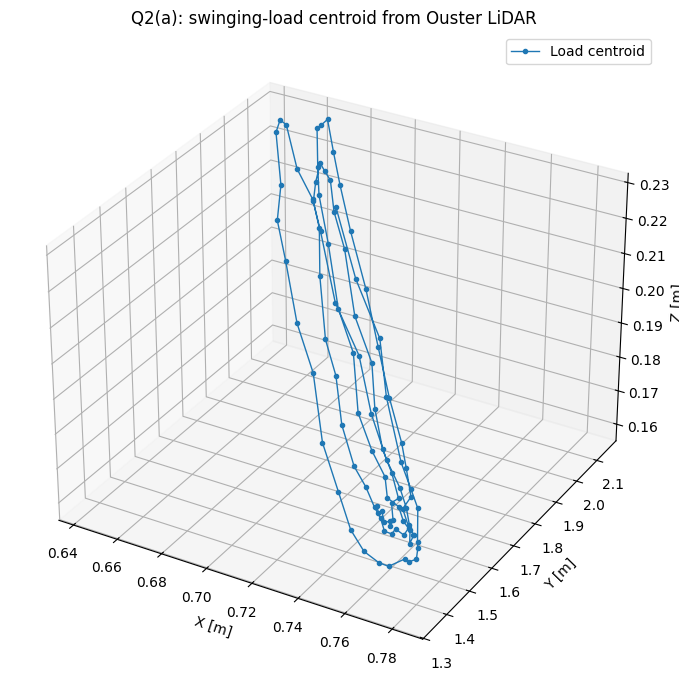

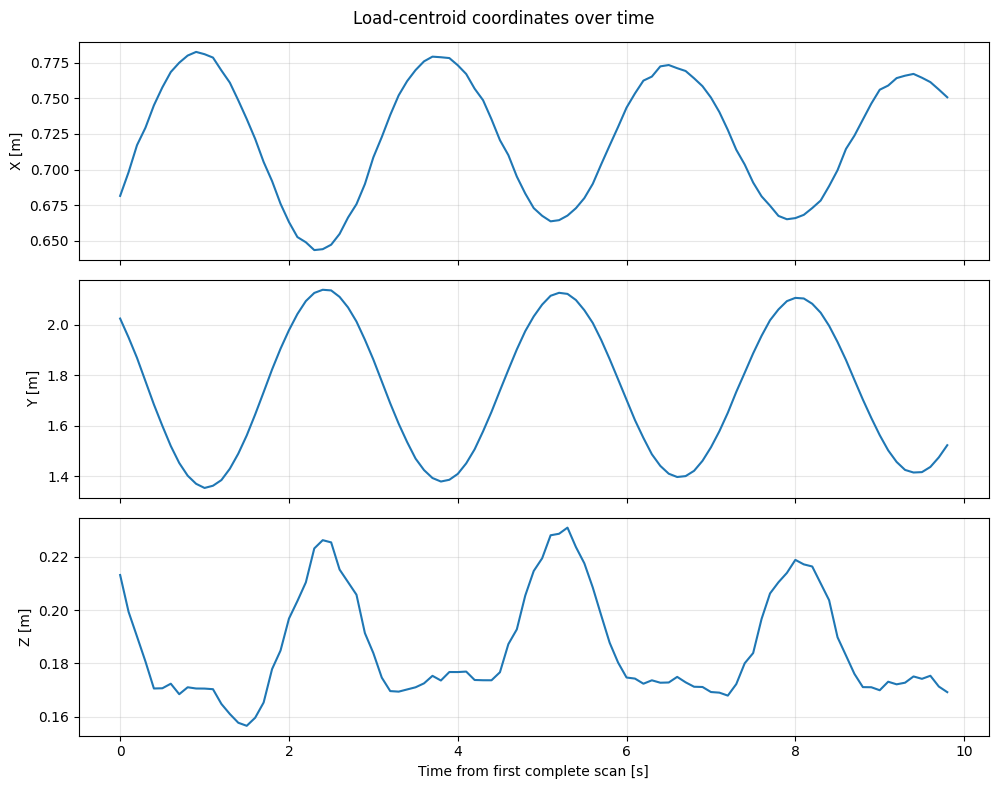

In [2]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    load_centers[load_valid, 0],
    load_centers[load_valid, 1],
    load_centers[load_valid, 2],
    "o-",
    markersize=3,
    linewidth=1,
    label="Load centroid",
)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Q2(a): swinging-load centroid from Ouster LiDAR")
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for axis, coordinate, label in zip(axes, range(3), ("X", "Y", "Z")):
    axis.plot(frame_times_s[load_valid], load_centers[load_valid, coordinate])
    axis.set_ylabel(f"{label} [m]")
    axis.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time from first complete scan [s]")
fig.suptitle("Load-centroid coordinates over time")
fig.tight_layout()
plt.show()

### Q2(b): KISS-ICP method and interpretation

KISS-ICP (Keep It Small and Simple ICP) estimates LiDAR odometry by aligning each scan to a local voxel map. It filters and voxel-downsamples points, predicts the next pose from recent motion, performs robust point-to-map ICP, then updates the pose, local map, and adaptive correspondence threshold. It is useful when a LiDAR-equipped platform needs local motion estimates without camera imagery or a learned model.

Its limitations matter here: pose estimates can drift over time, become unreliable in geometrically repetitive or sparse scenes, and be biased by moving objects. This recording uses a stationary sensor, so near-zero KISS-ICP motion is expected; it does not mean the load is stationary. KISS-ICP estimates the sensor pose, not the object's pose. The next cell transforms each detected load centroid into the first-scan reference frame using the corresponding estimated sensor pose. The transformed centroid provides position only; it is not a full rigid-body orientation estimate for the load.

KISS-ICP poses estimated: 99
Maximum estimated sensor translation from first scan [m]: 0.0046
Maximum estimated sensor rotation from first scan [deg]: 0.0191
First sensor pose [4x4]:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


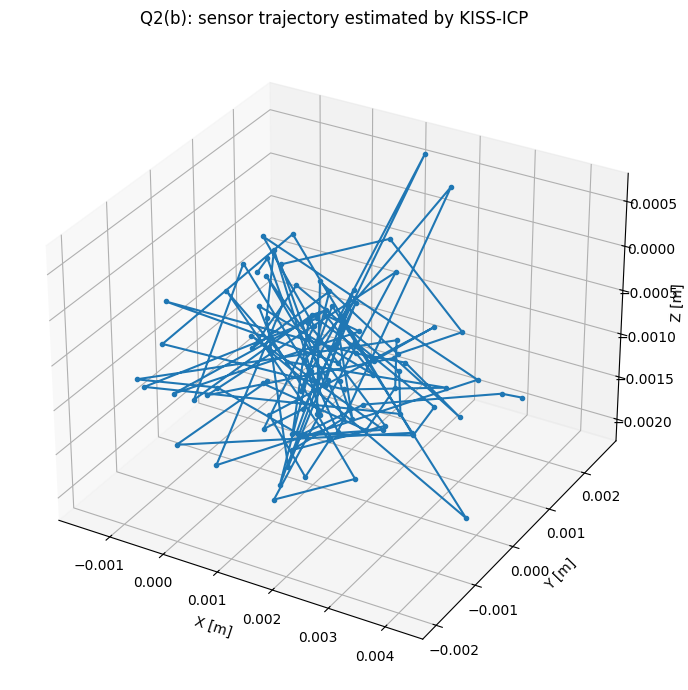

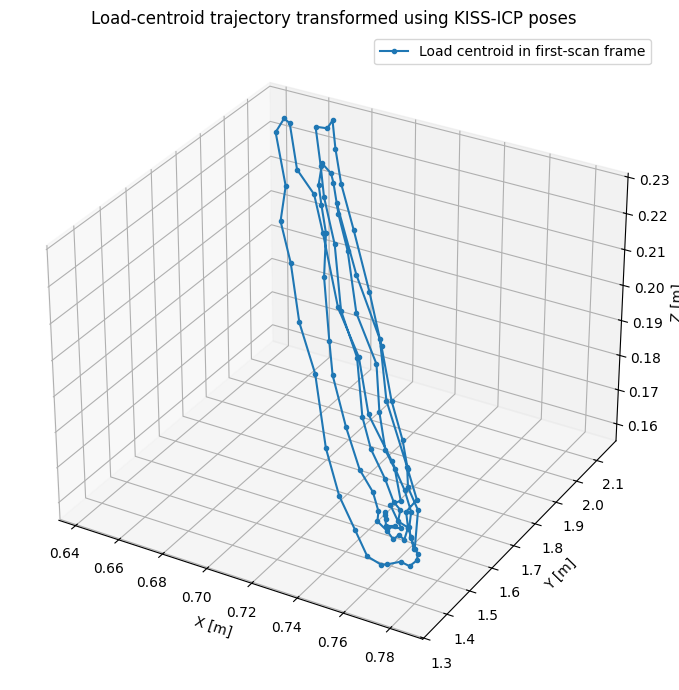

In [3]:
# KISS-ICP poses map each sensor scan into the first-scan reference frame.
load_centers_reference = np.full_like(load_centers, np.nan)
for index in np.flatnonzero(load_valid):
    load_centers_reference[index] = (
        sensor_poses[index, :3, :3] @ load_centers[index]
        + sensor_poses[index, :3, 3]
    )

sensor_translation = sensor_poses[:, :3, 3]
rotation_cos = np.clip(
    (np.trace(sensor_poses[:, :3, :3], axis1=1, axis2=2) - 1.0) / 2.0,
    -1.0,
    1.0,
)
sensor_rotation_deg = np.degrees(np.arccos(rotation_cos))
print(f"KISS-ICP poses estimated: {len(sensor_poses)}")
print(
    "Maximum estimated sensor translation from first scan [m]:",
    round(float(np.linalg.norm(sensor_translation, axis=1).max()), 4),
)
print(
    "Maximum estimated sensor rotation from first scan [deg]:",
    round(float(sensor_rotation_deg.max()), 4),
)
print("First sensor pose [4x4]:")
print(np.round(sensor_poses[0], 4))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(sensor_translation[:, 0], sensor_translation[:, 1], sensor_translation[:, 2], "o-", markersize=3)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Q2(b): sensor trajectory estimated by KISS-ICP")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    load_centers_reference[load_valid, 0],
    load_centers_reference[load_valid, 1],
    load_centers_reference[load_valid, 2],
    "o-",
    markersize=3,
    label="Load centroid in first-scan frame",
)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Load-centroid trajectory transformed using KISS-ICP poses")
ax.legend()
plt.tight_layout()
plt.show()

### Results from the supplied recording

The decoder produced 99 complete scans, and the load cluster was detected in all 99. The tracked centroid was within X = 0.643-0.783 m, Y = 1.354-2.139 m, and Z = 0.157-0.231 m. The 0.785 m span in Y shows the swinging motion in this recording.

KISS-ICP returned a pose for each scan. The maximum estimated sensor displacement from the first scan was 0.0046 m and the maximum rotation was 0.0191 degrees, consistent with a stationary sensor. These near-zero sensor-motion estimates are not the swinging-load trajectory; use the centroid plot for that. The transformed centroid coordinates are in the first-scan reference frame.

# Q3. Camera-Lidar fusion

## (a)

### Task:
Get familiar with the KITTI data set. There are multiple cameras and Lidar used. It contains information about images taken from cameras, point cloud taken from lidar, and camera matrices. Illustrate your understanding in presentation.

### Approach:
1. Inspect the KITTI training data structure.
2. Understand what the camera images, LiDAR point clouds, calibration files, and labels contain.
3. Explain how the camera and LiDAR data are related through the calibration matrices.
4. Use examples from the training data to illustrate the dataset structure.

### KITTI: sensors, files, and coordinate frames

KITTI's 3D-detection recordings associate camera images with Velodyne LiDAR scans and calibration/annotation files. In a full object-detection sequence, corresponding files share a frame identifier, for example:

- `image_2/000000.png`: rectified colour image from camera 2.
- `velodyne/000000.bin`: binary float32 records `(x, y, z, reflectance)` in the LiDAR frame.
- `calib/000000.txt`: camera projection matrices (`P0`-`P3`), rectification (`R0_rect`), and the LiDAR-to-camera transform (`Tr_velo_to_cam`).
- `label_2/000000.txt`: object classes, image boxes, 3D dimensions, positions, and yaw labels for the corresponding frame.

The transform chain is `point_camera_rect = R0_rect @ Tr_velo_to_cam @ point_lidar`, with matrices made homogeneous where necessary. Project to camera 2 with `pixel_h = P2 @ point_camera_rect`, then `u = pixel_h[0]/pixel_h[2]` and `v = pixel_h[1]/pixel_h[2]`. Keep points in front of the camera (`pixel_h[2] > 0`) and inside the image. Calibration is essential: the raw sensor coordinate axes and units are not interchangeable.

**Important data-scope note:** the local `Dataset_KITTI` folder is the Ultralytics YOLO detection subset, not the original synchronized KITTI sensor release. It contains JPG images and normalized 2D boxes, but no `velodyne`, `calib`, or original `label_2` directories. The example below therefore visualizes the available image annotations; it does not pretend to show LiDAR projected onto that image. To make a real camera–LiDAR overlay, download the matching KITTI image, Velodyne, calibration, and labels for the same frame IDs.

### Presentation-ready outline

1. **What KITTI records:** synchronized driving scenes; camera views provide appearance and LiDAR provides sparse 3D geometry/range.
2. **How files correspond:** same frame ID links an image, a Velodyne scan, calibration, and object labels. A `.bin` scan stores repeated float32 `(x, y, z, reflectance)` values.
3. **How fusion works:** transform LiDAR coordinates into the rectified camera frame, project through `P2`, discard points behind/outside the camera image, then overlay the remaining projected points and compare with labels.
4. **What we inspected locally:** 150 train + 40 validation JPEGs and matching YOLO-format 2D boxes. This subset has no paired LiDAR or calibration files, so a measured point-cloud overlay requires obtaining the matching raw KITTI files first.

The figure in the next cell is a real annotated subset image. It demonstrates the image/2D-label relationship; it is not a camera–LiDAR fusion result.

Dataset subset: c:\Users\resjw\Downloads\Dataset_KITTI\kitti_car_subset-54816d98
Configured classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}
Split summary: {'train': {'images': 150, 'label_files': 150, 'missing_labels': 0}, 'val': {'images': 40, 'label_files': 40, 'missing_labels': 0}}
Annotated boxes by class: {'car': 833, 'van': 87, 'truck': 34, 'pedestrian': 99, 'cyclist': 21, 'tram': 19, 'misc': 23}
Full KITTI image_2/ present: False
Full KITTI velodyne/ present: False
Full KITTI calib/ present: False
Full KITTI label_2/ present: False


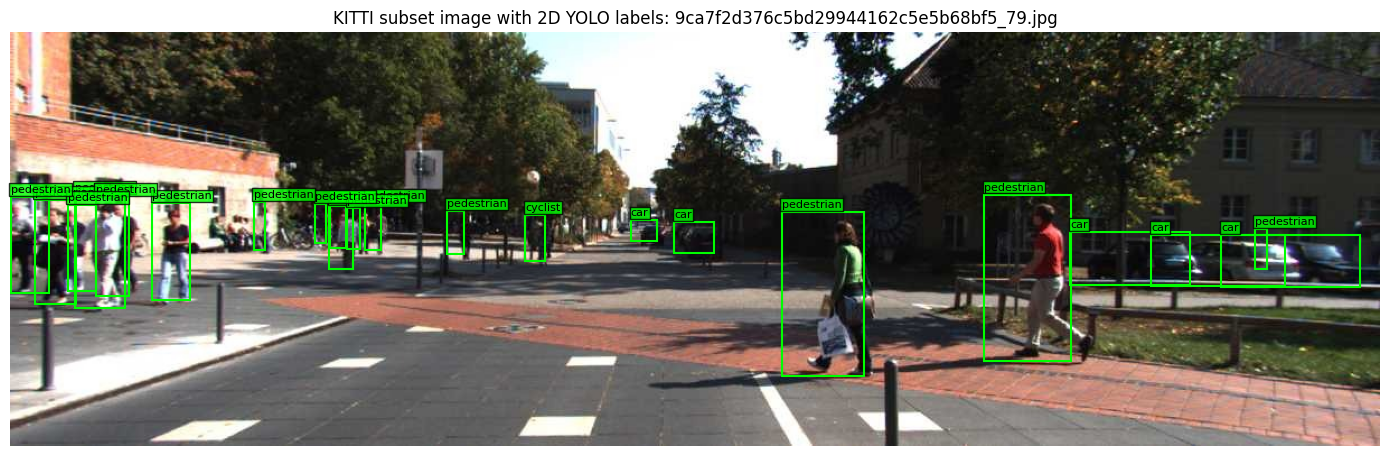

In [5]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml

KITTI_SEARCH_ROOTS = [
    Path.cwd() / "Dataset_KITTI",
    Path.cwd() / "MAS512_Group9_data" / "Dataset_KITTI",
]
kitti_root = next((root for root in KITTI_SEARCH_ROOTS if root.is_dir()), None)
if kitti_root is None:
    raise FileNotFoundError(
        "Could not find Dataset_KITTI. Set kitti_root to the folder containing "
        "the downloaded KITTI subset."
    )
subsets = sorted(kitti_root.glob("kitti_car_subset-*"))
if not subsets:
    raise FileNotFoundError(f"No kitti_car_subset-* directory found under {kitti_root}")
kitti_subset = subsets[0]
data_yaml = kitti_subset / "data.yaml"
if not data_yaml.is_file():
    raise FileNotFoundError(f"Missing dataset metadata: {data_yaml}")
with data_yaml.open(encoding="utf-8") as file:
    kitti_config = yaml.safe_load(file)
class_names = {int(key): value for key, value in kitti_config["names"].items()}

split_counts = {}
class_counts = Counter()
for split in ("train", "val"):
    image_dir = kitti_subset / "images" / split
    label_dir = kitti_subset / "labels" / split
    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))
    missing_labels = [image.name for image in images if not (label_dir / f"{image.stem}.txt").is_file()]
    split_counts[split] = {"images": len(images), "label_files": len(labels), "missing_labels": len(missing_labels)}
    for label_file in labels:
        for line_number, line in enumerate(label_file.read_text(encoding="utf-8").splitlines(), start=1):
            if not line.strip():
                continue
            values = line.split()
            if len(values) != 5:
                raise ValueError(f"Unexpected YOLO label at {label_file}:{line_number}: {line}")
            class_id = int(float(values[0]))
            if class_id not in class_names:
                raise ValueError(f"Unknown class id {class_id} in {label_file}")
            class_counts[class_id] += 1

print("Dataset subset:", kitti_subset)
print("Configured classes:", class_names)
print("Split summary:", split_counts)
print("Annotated boxes by class:", {class_names[key]: count for key, count in sorted(class_counts.items())})
for raw_folder in ("image_2", "velodyne", "calib", "label_2"):
    print(f"Full KITTI {raw_folder}/ present:", (kitti_subset / raw_folder).is_dir())

train_images = sorted((kitti_subset / "images" / "train").glob("*.jpg"))
if not train_images:
    raise RuntimeError(f"No training images found under {kitti_subset / 'images' / 'train'}")
sample_image_path = max(
    train_images,
    key=lambda path: len((kitti_subset / "labels" / "train" / f"{path.stem}.txt").read_text(encoding="utf-8").splitlines()),
)
sample_label_path = kitti_subset / "labels" / "train" / f"{sample_image_path.stem}.txt"
image = Image.open(sample_image_path).convert("RGB")
image_width, image_height = image.size
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(image)
with sample_label_path.open(encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        class_id, x_center, y_center, box_width, box_height = map(float, line.split())
        left = (x_center - box_width / 2) * image_width
        top = (y_center - box_height / 2) * image_height
        width = box_width * image_width
        height = box_height * image_height
        ax.add_patch(Rectangle((left, top), width, height, fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(left, max(0, top - 4), class_names[int(class_id)], color="black", fontsize=8,
                bbox={"facecolor": "lime", "alpha": 0.8, "pad": 1})
ax.set_title(f"KITTI subset image with 2D YOLO labels: {sample_image_path.name}")
ax.axis("off")
plt.tight_layout()
plt.show()

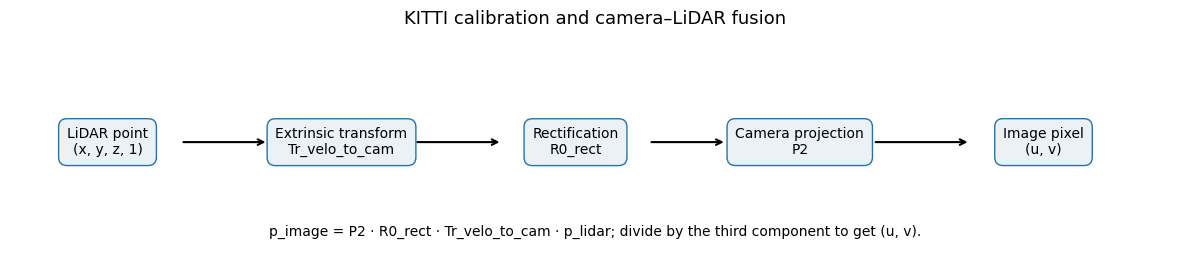

In [6]:
# Coordinate-frame flow for a KITTI LiDAR-to-camera projection.
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 2.8)
ax.axis("off")
steps = [
    (0.2, "LiDAR point\n(x, y, z, 1)"),
    (2.6, "Extrinsic transform\nTr_velo_to_cam"),
    (5.0, "Rectification\nR0_rect"),
    (7.3, "Camera projection\nP2"),
    (9.8, "Image pixel\n(u, v)"),
]
for x, label in steps:
    ax.text(x + 0.8, 1.45, label, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.6", "facecolor": "#eaf2f8", "edgecolor": "#2874a6"})
for (x1, _), (x2, _) in zip(steps, steps[1:]):
    ax.annotate("", xy=(x2 + 0.05, 1.45), xytext=(x1 + 1.55, 1.45),
                arrowprops={"arrowstyle": "->", "lw": 1.5})
ax.text(6, 0.35, "p_image = P2 · R0_rect · Tr_velo_to_cam · p_lidar; divide by the third component to get (u, v).",
        ha="center", va="center", fontsize=10)
ax.set_title("KITTI calibration and camera–LiDAR fusion", fontsize=13)
plt.tight_layout()
plt.show()

### Inspection results

The available subset contains **150 training** and **40 validation** images, with a matching YOLO label file for every image. The boxes are normalized 2D `(class, x_center, y_center, width, height)` annotations. In this subset the detected-box counts are: car 833, van 87, pedestrian 99, truck 34, cyclist 21, misc 23, and tram 19.

The subset does **not** include the matching original `velodyne/`, `calib/`, or KITTI `label_2/` files. The annotated image and calibration-flow diagram illustrate the available data and the fusion method, but a true projected LiDAR overlay cannot be computed from these files alone.

# Q3. KITTI camera–LiDAR fusion

The local 190-image KITTI subset used in Q3 contains only images and 2D YOLO annotations. To complete the sensor-fusion task without downloading the full 46.08 GB dataset, I use five matched KITTI-format training frames: `000001`, `000004`, `000008`, `000010`, and `000016`. Each frame has a left-camera image, Velodyne scan, calibration, and KITTI 3D labels. The five samples total about **13.5 MB**.

Sample source: [xuehaipiaoxiang/kitti_mini](https://github.com/xuehaipiaoxiang/kitti_mini/tree/af8f29866a7aebbd39234b161e405daa9f9e13e8/kitti_tiny_3D/training) (pinned repository revision). The samples are saved under `KITTI_Q4_samples/training` in Downloads.

For each frame, the locally available `YOLO_kitti_car.pt` model predicts 2D vehicle boxes. Velodyne points are projected onto the rectified camera image using `P2`, `R0_rect`, and `Tr_velo_to_cam`; projected points are colored by their range from the LiDAR sensor. The highest-confidence vehicle detection is used for the range estimate: the 20th percentile of LiDAR ranges inside its box, which favors the near surface when background points also fall in the box. The KITTI `label_2` box is used only to match the detection for evaluation; its 3D location supplies the ground-truth range after conversion back to the LiDAR frame.

The code below reports the five per-frame estimates and absolute errors, their mean absolute error, and overlays detections, ground-truth boxes, and projected LiDAR points. This is a five-frame demonstration, not a full-dataset benchmark.

,frame,YOLO class,confidence,KITTI class,box IoU,LiDAR points,LiDAR range (m),GT range (m),absolute error (m)
0,000001,car,0.30,Truck,0.95,74,63.60,69.73,6.13
1,000004,car,0.53,Car,0.93,116,40.06,41.67,1.61
2,000008,car,0.89,Car,0.86,108,32.57,34.29,1.71
3,000010,car,0.79,Car,0.91,1354,7.60,7.25,0.35
4,000016,car,0.78,Car,0.89,86,31.63,33.75,2.12


Five-frame mean absolute range error: 2.38 m


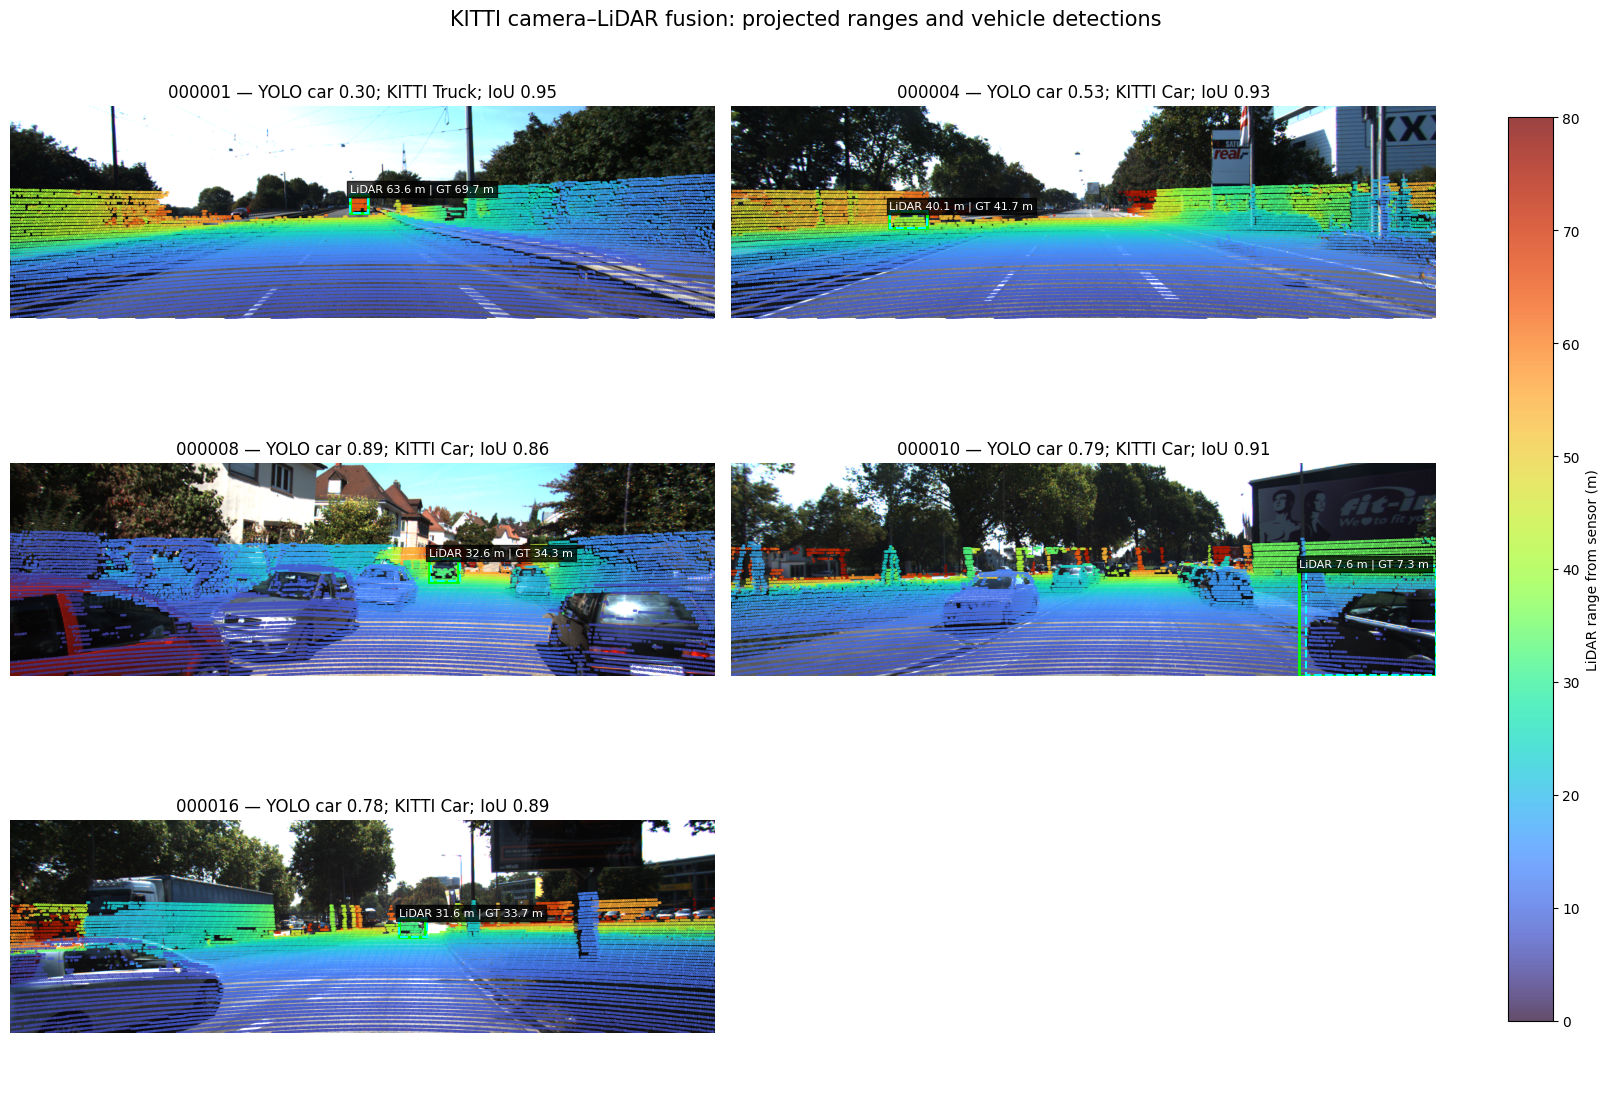

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

Q4_DATA_ROOT = Path(r"C:\Users\resjw\Downloads\KITTI_Q4_samples\training")
Q4_MODEL_PATH = Path(r"C:\Users\resjw\Downloads\YOLO_kitti_car.pt")
Q4_SAMPLE_IDS = ["000001", "000004", "000008", "000010", "000016"]
Q4_VEHICLE_CLASSES = {"car", "van", "truck"}

required_paths = [Q4_MODEL_PATH]
for frame_id in Q4_SAMPLE_IDS:
    required_paths.extend(
        [
            Q4_DATA_ROOT / "image_2" / f"{frame_id}.png",
            Q4_DATA_ROOT / "velodyne" / f"{frame_id}.bin",
            Q4_DATA_ROOT / "calib" / f"{frame_id}.txt",
            Q4_DATA_ROOT / "label_2" / f"{frame_id}.txt",
        ]
    )
missing_paths = [path for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError("Missing Q4 input files:\n" + "\n".join(map(str, missing_paths)))


def q4_read_calibration(path):
    calibration = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if ":" not in line:
            continue
        key, values = line.split(":", 1)
        calibration[key] = np.array([float(value) for value in values.split()])

    expected_sizes = {"P2": 12, "R0_rect": 9, "Tr_velo_to_cam": 12}
    for key, size in expected_sizes.items():
        if key not in calibration or calibration[key].size != size:
            raise ValueError(f"Invalid or missing {key} calibration in {path}")
    return calibration


def q4_read_labels(path):
    labels = []
    for line_number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), 1):
        fields = line.split()
        if not fields or fields[0] == "DontCare":
            continue
        if len(fields) != 15:
            raise ValueError(f"Expected 15 KITTI label fields at {path}:{line_number}")
        labels.append(
            {
                "class": fields[0],
                "bbox": np.array([float(value) for value in fields[4:8]]),
                "location_rect": np.array([float(value) for value in fields[11:14]]),
            }
        )
    return labels


def q4_box_iou(box_a, box_b):
    left = max(box_a[0], box_b[0])
    top = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2])
    bottom = min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def q4_project_lidar(frame_id, calibration, image_size):
    point_path = Q4_DATA_ROOT / "velodyne" / f"{frame_id}.bin"
    raw_points = np.fromfile(point_path, dtype=np.float32)
    if raw_points.size == 0 or raw_points.size % 4:
        raise ValueError(f"Invalid XYZI point data in {point_path}")
    points_velo = raw_points.reshape(-1, 4)[:, :3].astype(np.float64)

    transform = calibration["Tr_velo_to_cam"].reshape(3, 4)
    rectification = calibration["R0_rect"].reshape(3, 3)
    projection = calibration["P2"].reshape(3, 4)
    points_rect = rectification @ (transform[:, :3] @ points_velo.T + transform[:, 3:4])
    pixels_h = projection[:, :3] @ points_rect + projection[:, 3:4]
    denominator = pixels_h[2]
    with np.errstate(divide="ignore", invalid="ignore"):
        u = pixels_h[0] / denominator
        v = pixels_h[1] / denominator
    ranges = np.linalg.norm(points_velo, axis=1)
    width, height = image_size
    valid = (
        (points_rect[2] > 0)
        & (denominator > 0)
        & np.isfinite(u)
        & np.isfinite(v)
        & (u >= 0)
        & (u < width)
        & (v >= 0)
        & (v < height)
        & np.isfinite(ranges)
    )
    return u, v, ranges, valid, transform, rectification


def q4_ground_truth_range(label, transform, rectification):
    lidar_to_rect = np.eye(4)
    lidar_to_rect[:3, :3] = rectification @ transform[:, :3]
    lidar_to_rect[:3, 3] = rectification @ transform[:, 3]
    location_lidar = np.linalg.solve(lidar_to_rect, np.r_[label["location_rect"], 1.0])[:3]
    return float(np.linalg.norm(location_lidar))


q4_detector = YOLO(str(Q4_MODEL_PATH))
q4_rows = []
q4_visuals = []

for frame_id in Q4_SAMPLE_IDS:
    image_path = Q4_DATA_ROOT / "image_2" / f"{frame_id}.png"
    image = Image.open(image_path).convert("RGB")
    calibration = q4_read_calibration(Q4_DATA_ROOT / "calib" / f"{frame_id}.txt")
    labels = q4_read_labels(Q4_DATA_ROOT / "label_2" / f"{frame_id}.txt")
    vehicle_labels = [label for label in labels if label["class"].lower() in Q4_VEHICLE_CLASSES]
    if not vehicle_labels:
        raise RuntimeError(f"No labelled vehicle to validate in frame {frame_id}")

    prediction = q4_detector.predict(
        source=str(image_path), conf=0.25, iou=0.5, device="cpu", verbose=False
    )[0]
    detections = []
    for box in prediction.boxes:
        class_name = q4_detector.names[int(box.cls.item())].lower()
        if class_name in Q4_VEHICLE_CLASSES:
            detections.append(
                {
                    "class": class_name,
                    "confidence": float(box.conf.item()),
                    "bbox": box.xyxy[0].cpu().numpy().astype(float),
                }
            )
    if not detections:
        raise RuntimeError(f"YOLO found no vehicle in frame {frame_id}")
    detection = max(detections, key=lambda item: item["confidence"])

    matched_label = max(vehicle_labels, key=lambda label: q4_box_iou(detection["bbox"], label["bbox"]))
    overlap = q4_box_iou(detection["bbox"], matched_label["bbox"])
    if overlap < 0.2:
        raise RuntimeError(f"No matching KITTI vehicle box for frame {frame_id}; IoU={overlap:.2f}")

    u, v, ranges, valid, transform, rectification = q4_project_lidar(
        frame_id, calibration, image.size
    )
    x1, y1, x2, y2 = detection["bbox"]
    in_detection = valid & (u >= x1) & (u <= x2) & (v >= y1) & (v <= y2)
    point_count = int(in_detection.sum())
    if point_count < 20:
        raise RuntimeError(
            f"Only {point_count} projected LiDAR points in the detected box for frame {frame_id}"
        )

    estimated_range = float(np.percentile(ranges[in_detection], 20))
    ground_truth_range = q4_ground_truth_range(matched_label, transform, rectification)
    absolute_error = abs(estimated_range - ground_truth_range)
    q4_rows.append(
        {
            "frame": frame_id,
            "YOLO class": detection["class"],
            "confidence": detection["confidence"],
            "KITTI class": matched_label["class"],
            "box IoU": overlap,
            "LiDAR points": point_count,
            "LiDAR range (m)": estimated_range,
            "GT range (m)": ground_truth_range,
            "absolute error (m)": absolute_error,
        }
    )
    q4_visuals.append(
        {
            "frame": frame_id,
            "image": image,
            "u": u,
            "v": v,
            "ranges": ranges,
            "valid": valid,
            "detection": detection,
            "ground_truth": matched_label,
            "estimated_range": estimated_range,
            "ground_truth_range": ground_truth_range,
            "overlap": overlap,
        }
    )

q4_results = pd.DataFrame(q4_rows)
display(q4_results.round(2))
q4_mae = float(q4_results["absolute error (m)"].mean())
print(f"Five-frame mean absolute range error: {q4_mae:.2f} m")

fig, axes = plt.subplots(3, 2, figsize=(16, 11), constrained_layout=True)
color_mesh = None
for ax, sample in zip(axes.flat, q4_visuals):
    image = sample["image"]
    ax.imshow(image)
    color_mesh = ax.scatter(
        sample["u"][sample["valid"]],
        sample["v"][sample["valid"]],
        c=sample["ranges"][sample["valid"]],
        cmap="turbo",
        vmin=0,
        vmax=80,
        s=4,
        alpha=0.75,
        linewidths=0,
    )
    detection = sample["detection"]
    gt = sample["ground_truth"]
    x1, y1, x2, y2 = detection["bbox"]
    gx1, gy1, gx2, gy2 = gt["bbox"]
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2))
    ax.add_patch(
        Rectangle(
            (gx1, gy1), gx2 - gx1, gy2 - gy1,
            fill=False, edgecolor="cyan", linewidth=1.5, linestyle="--"
        )
    )
    ax.text(
        max(2, x1),
        max(14, y1 - 5),
        f"LiDAR {sample['estimated_range']:.1f} m | GT {sample['ground_truth_range']:.1f} m",
        color="white",
        fontsize=8,
        bbox={"facecolor": "black", "alpha": 0.75, "pad": 2},
    )
    ax.set_title(
        f"{sample['frame']} — YOLO {detection['class']} {detection['confidence']:.2f}; "
        f"KITTI {gt['class']}; IoU {sample['overlap']:.2f}"
    )
    ax.set_xlim(0, image.width)
    ax.set_ylim(image.height, 0)
    ax.axis("off")

axes.flat[-1].axis("off")
fig.colorbar(color_mesh, ax=list(axes.flat[:-1]), label="LiDAR range from sensor (m)", shrink=0.85)
fig.suptitle("KITTI camera–LiDAR fusion: projected ranges and vehicle detections", fontsize=15)
plt.show()

### Q3 results and interpretation

The five-frame test produced the following range comparisons (distance is measured from the LiDAR origin):

| Frame | YOLO class | KITTI class | Box IoU | LiDAR estimate (m) | Ground truth (m) | Absolute error (m) | LiDAR points in box |
|---|---|---|---:|---:|---:|---:|---:|
| 000001 | car | Truck | 0.95 | 63.60 | 69.73 | 6.13 | 74 |
| 000004 | car | Car | 0.93 | 40.06 | 41.67 | 1.61 | 116 |
| 000008 | car | Car | 0.86 | 32.57 | 34.29 | 1.71 | 108 |
| 000010 | car | Car | 0.91 | 7.60 | 7.25 | 0.35 | 1,354 |
| 000016 | car | Car | 0.89 | 31.63 | 33.75 | 2.12 | 86 |

**Mean absolute range error: 2.38 m** across these five frames. The predicted 2D boxes overlap their KITTI annotations well (IoU 0.86–0.95). The frame `000001` detection is spatially aligned with the Truck annotation but the model labels it as a car, so it is a classification error. Range error varies with point density and background returns inside the 2D box; the estimate is a LiDAR measurement, not the annotation's distance copied into the box.